# 05 – Modell A: Palepu-Logit

Ein einfaches Logit mit Palepus Variablen, geschätzt auf dem Training (FY2012–2017) und **einmal** auf dem Test (FY2020–2022) ausgewertet.

- **Unregularisiert** (keine Strafterme) und **ungewichtet** (keine Klassengewichte): Die vorhergesagten Wahrscheinlichkeiten sollen zur echten Basisrate passen. Genau das war Palepus methodische Lektion – eine künstlich auf 50/50 gebrachte Stichprobe treibt die Wahrscheinlichkeiten nach oben.
- **Standardfehler nach Firma geclustert:** Dieselbe Firma taucht in mehreren Jahren auf; ihre Zeilen sind nicht unabhängig. Clustern macht die Standardfehler (und damit die p-Werte) ehrlicher.
- Daten: `data/processed/model_data_palepu.csv` aus Notebook 04 (schon gekappt und aufgefüllt, Grenzen nur aus dem Training).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from pathlib import Path

Y = "y_pe_main_h3"
data = pd.read_csv(Path("..") / "data" / "processed" / "model_data_palepu.csv", dtype={"cik": str})

palepu_vars = ["roe", "sales_growth_1y", "liquidity", "leverage", "grdummy", "idummy",
               "log_assets", "float_to_book", "float_to_earnings"]
indicators = sorted(c for c in data.columns if c.endswith("_missing"))
X_COLS = palepu_vars + indicators

train = data[data["split"] == "train"]
test = data[data["split"] == "test"]
print(f"Training: {len(train):,} Zeilen, {int(train[Y].sum())} Positive ({train[Y].mean():.2%})")
print(f"Test:     {len(test):,} Zeilen, {int(test[Y].sum())} Positive ({test[Y].mean():.2%})")
print("Variablen:", X_COLS)

Training: 18,058 Zeilen, 167 Positive (0.92%)
Test:     9,596 Zeilen, 70 Positive (0.73%)
Variablen: ['roe', 'sales_growth_1y', 'liquidity', 'leverage', 'grdummy', 'idummy', 'log_assets', 'float_to_book', 'float_to_earnings', 'float_to_book_missing', 'float_to_earnings_missing', 'grdummy_missing', 'liquidity_missing', 'roe_missing', 'sales_growth_1y_missing']


## 1. Schätzen auf dem Training

In [2]:
X_train = sm.add_constant(train[X_COLS])            # Konstante (Achsenabschnitt) hinzufügen
logit = sm.Logit(train[Y], X_train)
result = logit.fit(method="newton", maxiter=100, disp=False,
                   cov_type="cluster", cov_kwds={"groups": train["cik"]})   # nach Firma geclustert
print("Konvergiert:", result.mle_retvals["converged"])
print(f"Firmen (Cluster): {train['cik'].nunique():,}")

Konvergiert: True
Firmen (Cluster): 4,763


## 2. Koeffizienten im Vergleich mit Palepu (1986)

- **Odds Ratio (OR)** = e^Koeffizient: um welchen Faktor sich die Chance ändert, Ziel zu werden, wenn die Variable um **eine Einheit** steigt. OR > 1 heißt höhere, OR < 1 niedrigere Chance.
- Weil die Einheiten sehr verschieden sind (ein Punkt Kurs-Gewinn-Verhältnis ist winzig, ein Punkt Verschuldung riesig), zeigen wir zusätzlich das **OR je Standardabweichung** (im Training) – das macht die Stärke vergleichbar.
- **Palepu erwartet**: Vorzeichen aus seiner Table 1. Für Wachstum, Liquidität und Verschuldung sagt er ausdrücklich *kein* Vorzeichen voraus, weil unklar ist, welche Art Ungleichgewicht überwiegt.
- **Palepu Ergebnis**: Model 2 aus Table 3 (ROE aus Model 4, wo ROE die Überrendite AER ersetzt). AER selbst haben wir nicht (Aktienrenditen sind nicht in SEC-Daten).
- **Achtung bei den Definitionen:** Palepus Verschuldung ist Schulden/Eigenkapital, seine Größe sind Netto-Buchvermögen (nicht logarithmiert), GRDUMMY nutzt den Mittelwert statt Median und IDUMMY 4-stellige statt 2-stellige SIC. Vergleichbar sind deshalb nur die **Vorzeichen**, nicht die Zahlen.

In [3]:
palepu = pd.DataFrame({
    #                    Palepu-Variable,              erwartet (Table 1), Ergebnis (Table 3)
    "roe":               ["ROE",                       "−",     "n.s. (Model 4)"],
    "sales_growth_1y":   ["Growth",                    "keins", "− (sig.)"],
    "liquidity":         ["Liquidity",                 "keins", "n.s."],
    "leverage":          ["Leverage (Schulden/EK)",    "keins", "− (sig.)"],
    "grdummy":           ["GRDUMMY",                   "+",     "+ (sig., 10 %)"],
    "idummy":            ["IDUMMY",                    "+",     "− (sig.)"],
    "log_assets":        ["Size (Netto-Buchvermögen)", "−",     "− (sig.)"],
    "float_to_book":     ["Market-to-book",            "−",     "n.s."],
    "float_to_earnings": ["P/E",                       "−",     "n.s."],
}, index=["Palepu-Variable", "Palepu erwartet", "Palepu Ergebnis"]).T

def our_result(coef, p):
    """Vorzeichen, wenn signifikant auf 10 %, sonst n.s."""
    if p >= 0.10:
        return "n.s."
    level = "sig." if p < 0.05 else "sig., 10 %"
    return f"{'+' if coef > 0 else '−'} ({level})"

sd = train[X_COLS].std()
table = pd.DataFrame({
    "Koeffizient": result.params,
    "Std.-Fehler (Cluster)": result.bse,
    "p-Wert": result.pvalues,
    "Odds Ratio": np.exp(result.params),
    "OR je SD": np.exp(result.params * sd.reindex(result.params.index)),
})
table["unser Ergebnis"] = [our_result(c, p) for c, p in zip(table["Koeffizient"], table["p-Wert"])]
table = table.join(palepu)

def agrees(row):
    """Stimmt unser Ergebnis mit Palepus Ergebnis überein (Vorzeichen bzw. beide n.s.)?"""
    if pd.isna(row["Palepu Ergebnis"]):
        return ""
    ours, his = row["unser Ergebnis"][0], row["Palepu Ergebnis"][0]   # erstes Zeichen: '+', '−' oder 'n'
    return "ja" if ours == his else "nein"

table["gleich wie Palepu?"] = table.apply(agrees, axis=1)
pd.set_option("display.max_columns", None)
table.round({"Koeffizient": 4, "Std.-Fehler (Cluster)": 4, "p-Wert": 3, "Odds Ratio": 3, "OR je SD": 3}).fillna("")

,Koeffizient,Std.-Fehler (Cluster),p-Wert,Odds Ratio,OR je SD,unser Ergebnis,Palepu-Variable,Palepu erwartet,Palepu Ergebnis,gleich wie Palepu?
const,-5.4462,1.0499,0.000,0.004,,− (sig.),,,,
roe,0.0720,0.1996,0.719,1.075,1.058,n.s.,ROE,−,n.s. (Model 4),ja
sales_growth_1y,-0.0740,0.1172,0.527,0.929,0.961,n.s.,Growth,keins,− (sig.),nein
liquidity,0.1808,0.1471,0.219,1.198,1.186,n.s.,Liquidity,keins,n.s.,ja
leverage,-0.1658,0.3724,0.656,0.847,0.944,n.s.,Leverage (Schulden/EK),keins,− (sig.),nein
grdummy,-0.8208,0.2732,0.003,0.440,0.74,− (sig.),GRDUMMY,+,"+ (sig., 10 %)",nein
idummy,0.3582,0.2031,0.078,1.431,1.171,"+ (sig., 10 %)",IDUMMY,+,− (sig.),nein
log_assets,0.0448,0.0478,0.349,1.046,1.123,n.s.,Size (Netto-Buchvermögen),−,− (sig.),nein
float_to_book,0.0014,0.0028,0.617,1.001,1.033,n.s.,Market-to-book,−,n.s.,ja
float_to_earnings,-0.0002,0.0008,0.779,1.000,0.972,n.s.,P/E,−,n.s.,ja


**Ergebnis:** Nur zwei Variablen tragen etwas bei, wenn alle gleichzeitig im Modell sind: **`grdummy` ist negativ und signifikant** (OR 0,44, p = 0,003) – Firmen mit Wachstums-Ressourcen-Ungleichgewicht werden *seltener* Ziel, genau umgekehrt wie bei Palepu. **`idummy` ist positiv** (OR 1,43, p = 0,08, nur auf 10 %-Niveau) – PE-Aktivität in der Branche im Vorjahr erhöht die Chance; das widerspricht Palepus Ergebnis, passt aber zu seiner ursprünglichen Hypothese. Alle anderen Variablen sind nicht signifikant, auch Verschuldung und Größe, die bei Palepu signifikant negativ waren. Dass Verschuldung im Median-Vergleich (Notebook 02/03) höher war, hier aber nicht zählt, heißt: Neben den anderen Variablen liefert sie keine zusätzliche Information. Übereinstimmung mit Palepus Ergebnis: 4 von 9 (ROE, Liquidität, Market-to-book, P/E jeweils nicht signifikant).

## 3. Erklärungskraft: McFadden-Pseudo-R²

McFadden-R² = 1 − (Log-Likelihood des Modells / Log-Likelihood eines Modells nur mit Konstante). Das ist genau Palepus „likelihood ratio index“. Bei ihm lag er zwischen 6,95 % und 12,45 % (Model 4, das unserem Aufbau mit ROE entspricht: 9,79 %). Vorsicht beim Vergleich: Palepu schätzte auf einer Stichprobe mit 39 % Zielen, wir auf der natürlichen Basisrate von unter 1 %.

In [4]:
print(f"McFadden-Pseudo-R² (Training): {result.prsquared:.2%}")
print(f"Log-Likelihood Modell: {result.llf:.1f} | nur Konstante: {result.llnull:.1f}")
print(f"Likelihood-Ratio-Test: Chi² = {result.llr:.1f}, p = {result.llr_pvalue:.2g}")

McFadden-Pseudo-R² (Training): 2.03%
Log-Likelihood Modell: -929.1 | nur Konstante: -948.3
Likelihood-Ratio-Test: Chi² = 38.5, p = 0.00077


**Ergebnis:** Das Modell erklärt nur **2,0 %** (McFadden), deutlich weniger als Palepus 9,8–12,5 %. Direkt vergleichbar ist das nicht, weil der Wert von der Zusammensetzung der Stichprobe abhängt (bei Palepu 39 % Ziele, bei uns 0,9 %). Der Likelihood-Ratio-Test ist aber signifikant (p < 0,001): Gemeinsam tragen die Variablen etwas bei, nur sehr wenig.

## 4. Einmalige Auswertung auf dem Test (FY2020–2022)

- **ROC-AUC**: Wahrscheinlichkeit, dass eine zufällige Ziel-Zeile einen höheren Score bekommt als eine zufällige Nicht-Ziel-Zeile (0,5 = Münzwurf, 1 = perfekt).
- **PR-AUC** (Average Precision): wie präzise die Treffer sind, wenn man die Liste von oben abarbeitet; der Zufallswert ist die **Basisrate**.
- **Oberstes Dezil**: Anteil aller Test-Ziele, die unter den 10 % Zeilen mit dem höchsten Score liegen (Zufall: 10 %).
- **95 %-Intervalle per Firmen-Bootstrap**: 1.000-mal werden Firmen (nicht einzelne Zeilen) mit Zurücklegen gezogen, weil die Jahre einer Firma zusammenhängen.

In [5]:
test = test.copy()
test["p_hat"] = result.predict(sm.add_constant(test[X_COLS], has_constant="add"))

def top_decile_capture(y, p):
    """Anteil der Positiven, die unter den 10 % höchsten Scores liegen."""
    n_top = int(np.ceil(0.10 * len(p)))
    top = np.argsort(-p)[:n_top]
    return y[top].sum() / y.sum()

def metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Basisrate": y.mean(), "Anteil Ziele im obersten Dezil": top_decile_capture(y, p)}

y_test, p_test = test[Y].to_numpy(), test["p_hat"].to_numpy()
point = metrics(y_test, p_test)

# Firmen-Bootstrap: Firmen mit Zurücklegen ziehen, alle Zeilen der gezogenen Firmen nehmen
rng = np.random.default_rng(20261028)
rows_by_firm = [idx for idx in test.reset_index(drop=True).groupby("cik").indices.values()]
draws = []
for _ in range(1000):
    pick = rng.integers(0, len(rows_by_firm), len(rows_by_firm))
    idx = np.concatenate([rows_by_firm[i] for i in pick])
    if y_test[idx].sum() == 0:              # ohne Positive ist keine AUC berechenbar
        continue
    draws.append(metrics(y_test[idx], p_test[idx]))
draws = pd.DataFrame(draws)

summary = pd.DataFrame({"Wert": point,
                        "95 %-KI unten": draws.quantile(0.025),
                        "95 %-KI oben": draws.quantile(0.975)})
print(f"Gültige Bootstrap-Ziehungen: {len(draws)} von 1000")
summary.round(4)

Gültige Bootstrap-Ziehungen: 1000 von 1000


,Wert,95 %-KI unten,95 %-KI oben
ROC-AUC,0.6340,0.5616,0.7111
PR-AUC,0.0136,0.0085,0.0305
Basisrate,0.0073,0.0052,0.0097
Anteil Ziele im obersten Dezil,0.1857,0.0943,0.2977


**Ergebnis:** Die **ROC-AUC liegt bei 0,63** (95 %-KI 0,56–0,71): besser als Zufall (das Intervall liegt über 0,5), aber eine schwache Trennung. Die PR-AUC von 1,4 % ist knapp doppelt so hoch wie die Basisrate von 0,73 %, und im obersten Dezil liegen **19 % der Test-Ziele** (KI 9–30 %) statt 10 % bei Zufall. Die Intervalle sind breit, weil der Test nur 70 positive Zeilen von 43 Firmen hat.

## 5. Kalibrierung auf dem Test

Passen die vorhergesagten Wahrscheinlichkeiten zu den tatsächlichen Häufigkeiten? Die Testzeilen werden nach ihrer Vorhersage in **10 gleich große Gruppen** (Quantile) geteilt; für jede Gruppe vergleichen wir die durchschnittliche Vorhersage (x) mit dem tatsächlichen Anteil der Ziele (y). Liegen die Punkte auf der Diagonale, ist das Modell gut kalibriert. **Lineare Achsen**, darunter ein Histogramm, wo die Vorhersagen liegen.

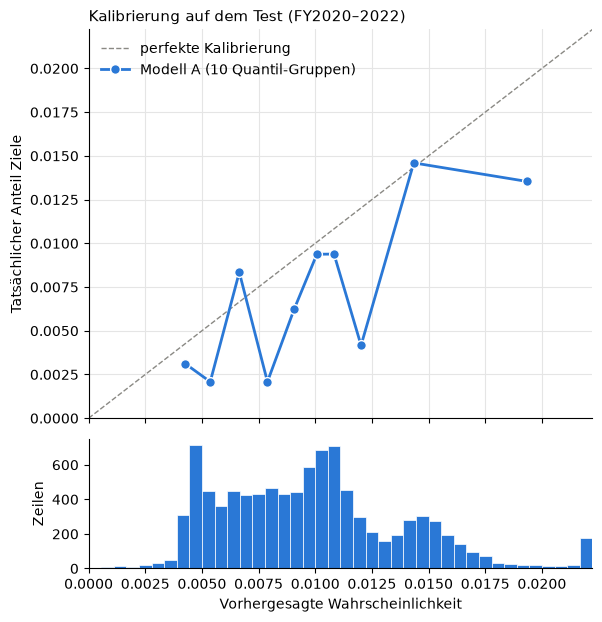

Vorhersagen oberhalb 0.022 (im letzten Balken gesammelt): 158
Mittlere Vorhersage im Test: 0.998% | tatsächliche Basisrate: 0.729%


,Vorhersage_Mittel,Anteil_Ziele,Zeilen,Ziele
bin,,,,
0,0.0043,0.0031,960,3
1,0.0054,0.0021,960,2
2,0.0066,0.0083,959,8
3,0.0079,0.0021,960,2
4,0.0091,0.0063,959,6
5,0.0101,0.0094,960,9
6,0.0108,0.0094,959,9
7,0.0120,0.0042,960,4
8,0.0143,0.0146,959,14


In [6]:
test["bin"] = pd.qcut(test["p_hat"], 10, labels=False, duplicates="drop")
calib = test.groupby("bin").agg(Vorhersage_Mittel=("p_hat", "mean"), Anteil_Ziele=(Y, "mean"),
                                Zeilen=(Y, "size"), Ziele=(Y, "sum"))

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
limit = max(calib["Vorhersage_Mittel"].max(), calib["Anteil_Ziele"].max()) * 1.15

fig, (ax, axh) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08})
ax.plot([0, limit], [0, limit], color=GRAY, linestyle="--", linewidth=1, label="perfekte Kalibrierung")
ax.plot(calib["Vorhersage_Mittel"], calib["Anteil_Ziele"], color=BLUE, linewidth=2,
        marker="o", markersize=7, markeredgecolor="white", label="Modell A (10 Quantil-Gruppen)")
ax.set_xlim(0, limit); ax.set_ylim(0, limit)
ax.set_ylabel("Tatsächlicher Anteil Ziele")
ax.set_title("Kalibrierung auf dem Test (FY2020–2022)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.grid(color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

# Histogramm: Vorhersagen oberhalb der Achsengrenze landen im letzten Balken
clipped = np.clip(test["p_hat"], 0, limit * 0.999)
axh.hist(clipped, bins=40, range=(0, limit), color=BLUE, edgecolor="white", linewidth=0.5)
axh.set_xlabel("Vorhergesagte Wahrscheinlichkeit")
axh.set_ylabel("Zeilen")
axh.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Vorhersagen oberhalb {limit:.3f} (im letzten Balken gesammelt): {(test['p_hat'] > limit).sum()}")
print(f"Mittlere Vorhersage im Test: {test['p_hat'].mean():.3%} | tatsächliche Basisrate: {test[Y].mean():.3%}")
calib.round(4)

**Ergebnis:** Anders als die alten Plots sieht die Kalibrierung jetzt so aus, wie sie soll: Die Punkte streuen **um die Diagonale**, und die Vorhersagen liegen im realistischen Bereich von 0,4 % bis 2 % statt künstlich hoch. Im Mittel sagt das Modell 1,0 % voraus, tatsächlich sind es 0,73 % – es überschätzt also um rund ein Drittel, weil die Basisrate im Training (0,92 %) höher war als im Test. Das Zickzack kommt daher, dass jede Gruppe nur 2–14 Ziele enthält; einzelne Ziele verschieben einen Punkt stark.

## 6. Nachbau von Palepus Fig. 1: Verteilung der Wahrscheinlichkeiten (Training)

Palepu zeigt, wie sich die geschätzten Übernahmewahrscheinlichkeiten von Zielen und Nicht-Zielen verteilen (bei ihm: Median 0,144 für Ziele, 0,087 für Nicht-Ziele). Je weiter die beiden Verteilungen auseinanderliegen, desto besser trennt das Modell. Damit die 167 Ziele neben den knapp 18.000 Nicht-Zielen sichtbar sind, zeigen wir je Gruppe den **Anteil** in jedem Intervall.

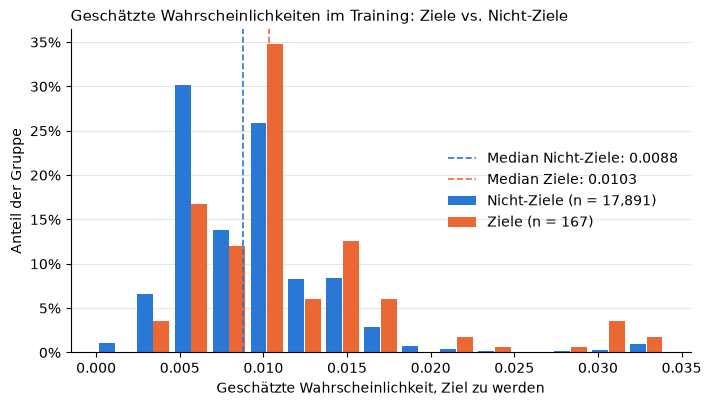

Median Ziele: 0.0103 | Median Nicht-Ziele: 0.0088 | Verhältnis: 1.18 (Palepu: 0.144 / 0.087 = 1.66)
Wahrscheinlichkeiten über 0.034 (im letzten Intervall gesammelt): 91


In [7]:
train = train.copy()
train["p_hat"] = result.predict(X_train)

upper = train["p_hat"].quantile(0.995)                 # gleich breite Intervalle bis zum 99,5-%-Punkt
edges = np.linspace(0, upper, 16)
mids = (edges[:-1] + edges[1:]) / 2
width = edges[1] - edges[0]

def share_per_bin(p):
    counts, _ = np.histogram(np.clip(p, 0, upper * 0.999), bins=edges)   # Ausreißer -> letztes Intervall
    return counts / counts.sum()

targets, non_targets = train.loc[train[Y] == 1, "p_hat"], train.loc[train[Y] == 0, "p_hat"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(mids - width * 0.22, share_per_bin(non_targets), width=width * 0.42, color=BLUE, label=f"Nicht-Ziele (n = {len(non_targets):,})")
ax.bar(mids + width * 0.22, share_per_bin(targets), width=width * 0.42, color=ORANGE, label=f"Ziele (n = {len(targets)})")
# Medianlinien (gestrichelt), mit Wert in der Legende
for med, color, name in [(non_targets.median(), BLUE, "Median Nicht-Ziele"), (targets.median(), ORANGE, "Median Ziele")]:
    ax.axvline(med, color=color, linestyle="--", linewidth=1.2, label=f"{name}: {med:.4f}")
ax.set_xlabel("Geschätzte Wahrscheinlichkeit, Ziel zu werden")
ax.set_ylabel("Anteil der Gruppe")
ax.set_title("Geschätzte Wahrscheinlichkeiten im Training: Ziele vs. Nicht-Ziele", loc="left", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, loc="center right")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Median Ziele: {targets.median():.4f} | Median Nicht-Ziele: {non_targets.median():.4f} "
      f"| Verhältnis: {targets.median() / non_targets.median():.2f} (Palepu: 0.144 / 0.087 = 1.66)")
print(f"Wahrscheinlichkeiten über {upper:.3f} (im letzten Intervall gesammelt): {(train['p_hat'] > upper).sum()}")

**Ergebnis:** Die Verteilungen von Zielen und Nicht-Zielen **überlappen fast vollständig**: Der Median der Ziele (1,03 %) ist nur 1,18-mal so hoch wie der der Nicht-Ziele (0,88 %); bei Palepu war das Verhältnis 1,66. Auch spätere Ziele bekommen fast nie mehr als 2–3 % Wahrscheinlichkeit – wie bei Palepu ist das Signal schwach („only a weak signal“), bei uns noch schwächer. Seine absoluten Werte (0,144 und 0,087) sind höher, weil allgemeine Übernahmen in den 1970ern viel häufiger waren als PE-Take-Privates heute; vergleichbar ist das Verhältnis, nicht die Höhe.

## 7. Palepu-Cutoff-Test

Palepu (1986, Abschnitt 4.2.1) übersetzt die Wahrscheinlichkeiten in eine Ja/Nein-Vorhersage: Eine Firma gilt als vorhergesagtes Ziel, wenn ihre Wahrscheinlichkeit über einem **Cutoff** liegt. Den Cutoff bestimmt er **nur aus der Schätzstichprobe** als den Punkt, an dem sich die Verteilungen von Zielen und Nicht-Zielen schneiden – darunter sind Nicht-Ziele häufiger, darüber Ziele. Modell A bleibt dabei unverändert.

**So bestimmen wir den Schnittpunkt:** Wie Palepu teilen wir den Bereich der Trainings-Wahrscheinlichkeiten (0 bis zum Maximum) in 10 gleich breite Intervalle und berechnen je Intervall den Anteil der Ziele und den Anteil der Nicht-Ziele, eingetragen am Intervall-Mittelpunkt. Wir verbinden die Punkte mit geraden Linien und nehmen die **erste Stelle, an der die Ziel-Linie die Nicht-Ziel-Linie von unten kreuzt** (lineare Interpolation zwischen den beiden Mittelpunkten); spätere Kreuzungen im dünn besetzten oberen Bereich zeigen wir, verwenden sie aber nicht.

In [8]:
# Palepus Tabelle 4 für unser Training: 10 gleich breite Intervalle von 0 bis zur größten Wahrscheinlichkeit
p_tr, y_tr = train["p_hat"].to_numpy(), train[Y].to_numpy()
edges10 = np.linspace(0, p_tr.max(), 11)
mid10 = (edges10[:-1] + edges10[1:]) / 2
f_targets = np.histogram(p_tr[y_tr == 1], bins=edges10)[0] / (y_tr == 1).sum()
f_non = np.histogram(p_tr[y_tr == 0], bins=edges10)[0] / (y_tr == 0).sum()
dist = pd.DataFrame({"Intervall": [f"{a:.4f}–{b:.4f}" for a, b in zip(edges10[:-1], edges10[1:])],
                     "Mittelpunkt": mid10.round(4),
                     "Ziele %": (100 * f_targets).round(1), "Nicht-Ziele %": (100 * f_non).round(1),
                     "Differenz (Ziele − Nicht-Ziele)": (100 * (f_targets - f_non)).round(1)})

# Alle Kreuzungen (Vorzeichenwechsel der Differenz), Schnittpunkt per linearer Interpolation
diff = f_targets - f_non
crossings = []
for i in range(len(diff) - 1):
    if diff[i] < 0 <= diff[i + 1] or diff[i] > 0 >= diff[i + 1]:
        x = mid10[i] + (mid10[i + 1] - mid10[i]) * (-diff[i]) / (diff[i + 1] - diff[i])
        crossings.append((x, "Ziele überholen" if diff[i] < 0 else "Nicht-Ziele überholen"))

cutoff = next(x for x, kind in crossings if kind == "Ziele überholen")   # erste Kreuzung von unten
display(dist.set_index("Intervall"))
print("Alle Kreuzungen:", [(round(float(x), 4), k) for x, k in crossings])
print(f"Cutoff (erste Kreuzung von unten): {cutoff:.4f}")

,Mittelpunkt,Ziele %,Nicht-Ziele %,Differenz (Ziele − Nicht-Ziele)
Intervall,,,,
0.0000–0.0049,0.0024,4.8,12.6,-7.8
0.0049–0.0097,0.0073,34.7,44.5,-9.8
0.0097–0.0146,0.0121,39.5,32.3,7.2
0.0146–0.0194,0.0170,12.6,8.4,4.2
0.0194–0.0243,0.0219,2.4,0.7,1.7
0.0243–0.0291,0.0267,0.6,0.2,0.4
0.0291–0.0340,0.0316,4.2,0.8,3.4
0.0340–0.0389,0.0364,1.2,0.3,0.9
0.0389–0.0437,0.0413,0.0,0.1,-0.1


Alle Kreuzungen: [(0.0101, 'Ziele überholen'), (0.041, 'Nicht-Ziele überholen')]
Cutoff (erste Kreuzung von unten): 0.0101


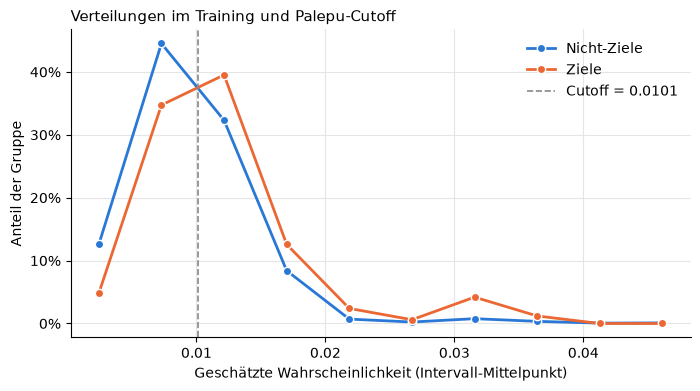

In [9]:
# Palepus Fig. 1 im Stil des Originals: Linien durch die Intervall-Mittelpunkte, Cutoff markiert
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mid10, f_non, color=BLUE, linewidth=2, marker="o", markersize=6, markeredgecolor="white", label="Nicht-Ziele")
ax.plot(mid10, f_targets, color=ORANGE, linewidth=2, marker="o", markersize=6, markeredgecolor="white", label="Ziele")
ax.axvline(cutoff, color=GRAY, linestyle="--", linewidth=1.2, label=f"Cutoff = {cutoff:.4f}")
ax.set_xlabel("Geschätzte Wahrscheinlichkeit (Intervall-Mittelpunkt)")
ax.set_ylabel("Anteil der Gruppe")
ax.set_title("Verteilungen im Training und Palepu-Cutoff", loc="left", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False)
ax.grid(color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [10]:
# Einmal auf den Test anwenden: vorhergesagtes Ziel, wenn Wahrscheinlichkeit >= Cutoff
pred = test["p_hat"] >= cutoff
actual = test[Y] == 1
n_t, n_n = int(actual.sum()), int((~actual).sum())
tp, tn = int((pred & actual).sum()), int((~pred & ~actual).sum())

ours = {"Cutoff": f"{cutoff:.4f}",
        "Firmenjahre insgesamt": f"{len(test):,}",
        "tatsächliche Ziele (Basisrate)": f"{n_t} ({n_t / len(test):.2%})",
        "als Ziel vorhergesagt": f"{int(pred.sum()):,}",
        "davon echte Ziele": f"{tp}",
        "Ziele korrekt erkannt": f"{tp / n_t:.1%} ({tp}/{n_t})",
        "Nicht-Ziele korrekt erkannt": f"{tn / n_n:.1%} ({tn:,}/{n_n:,})",
        "Gesamtgenauigkeit": f"{(tp + tn) / len(test):.1%}"}
palepu_holdout = {"Cutoff": "0.112",
                  "Firmenjahre insgesamt": "1,117",
                  "tatsächliche Ziele (Basisrate)": "30 (2.69%)",
                  "als Ziel vorhergesagt": "625",
                  "davon echte Ziele": "24",
                  "Ziele korrekt erkannt": "80.0% (24/30)",
                  "Nicht-Ziele korrekt erkannt": "44.7% (486/1,087)",
                  "Gesamtgenauigkeit": "45.7% (berechnet)"}
pd.DataFrame({"Modell A, Test 2020–2022": ours, "Palepu, Holdout 1980": palepu_holdout})

,"Modell A, Test 2020–2022","Palepu, Holdout 1980"
Cutoff,0.0101,0.112
Firmenjahre insgesamt,"9,596","1,117"
tatsächliche Ziele (Basisrate),70 (0.73%),30 (2.69%)
als Ziel vorhergesagt,"4,315",625
davon echte Ziele,46,24
Ziele korrekt erkannt,65.7% (46/70),80.0% (24/30)
Nicht-Ziele korrekt erkannt,"55.2% (5,257/9,526)","44.7% (486/1,087)"
Gesamtgenauigkeit,55.3%,45.7% (berechnet)


**Ergebnis:** Die Verteilungen kreuzen sich im Training bei **0,0101** (eine zweite Kreuzung bei 0,041 liegt im fast leeren Randbereich und wird nicht verwendet). Im Test werden damit **4.315 von 9.596 Firmenjahren** als Ziel vorhergesagt, davon sind 46 echte Ziele: **66 % der Ziele** und **55 % der Nicht-Ziele** werden richtig erkannt (Palepu: 80 % und 45 %). Wie bei Palepu ist der Preis eine Flut falscher Alarme – nur 1,1 % der vorhergesagten Ziele sind echte (Palepu: 3,8 %); im Verhältnis zur jeweiligen Basisrate ist das bei beiden fast dieselbe Verbesserung (1,46-fach bei uns, 1,43-fach bei Palepu).

## 8. Variante A2: GRDUMMY aufgeteilt (nur Training)

`grdummy` fasst zwei sehr verschiedene Firmentypen zusammen. Variante A2 trennt sie, um zu sehen, welcher den negativen Effekt aus Modell A treibt:

- **`grd_type1`** = niedriges Wachstum, hohe Liquidität, niedrige Verschuldung – das „Jensen-Free-Cashflow-Profil“ (reife Firma mit viel Geld und wenig Investitionsmöglichkeiten).
- **`grd_type2`** = hohes Wachstum, niedrige Liquidität, hohe Verschuldung (wachsende Firma, der das Geld fehlt).

Gleiche Zutaten und gleiche Regel wie `grdummy` (über/höchstens Median aller Stichprobenfirmen im selben Geschäftsjahr). Fehlt eine Zutat, sind beide 0; `grdummy_missing` bleibt unverändert. Palepu fragt in Modell 2/4 dasselbe – welcher Typ überwiegt –, dort über die zusätzlich aufgenommenen stetigen Variablen. **Modell A bleibt unverändert; A2 wird nur auf dem Training geschätzt, ohne Test-Auswertung.**

In [11]:
# Die Hoch/Niedrig-Einstufung braucht die ROHWERTE: In model_data sind fehlende Werte schon mit dem
# Median aufgefüllt, das würde die Jahresmediane verschieben. Deshalb die Zutaten neu aus der Pipeline holen.
DATA = Path("..") / "data" / "processed"
raw = (data[["accession", "fiscal_year"]]
       .merge(pd.read_csv(DATA / "firm_year_ratios.csv", usecols=["accession", "sales_growth_1y", "leverage"]),
              on="accession", how="left", validate="one_to_one")
       .merge(pd.read_csv(DATA / "firm_year_fundamentals.csv",
                          usecols=["accession", "cash", "liabilities_current", "total_assets"]),
              on="accession", how="left", validate="one_to_one"))
raw["liquidity"] = (raw["cash"] - raw["liabilities_current"]) / raw["total_assets"].where(raw["total_assets"] > 0)

def high_vs_year_median(col):
    """True = über dem Median des Geschäftsjahres (alle Stichprobenzeilen), NaN = Wert fehlt."""
    high = raw[col] > raw.groupby("fiscal_year")[col].transform("median")
    return high.where(raw[col].notna())

g, l, v = (high_vs_year_median(c) for c in ["sales_growth_1y", "liquidity", "leverage"])
data["grd_type1"] = ((g == False) & (l == True) & (v == False)).astype(int).to_numpy()   # wenig Wachstum, viel Geld
data["grd_type2"] = ((g == True) & (l == False) & (v == True)).astype(int).to_numpy()    # viel Wachstum, wenig Geld

# Kontrolle: beide Typen zusammen ergeben genau das bisherige grdummy, und bei fehlender Zutat sind beide 0
assert (data["grd_type1"] + data["grd_type2"] == data["grdummy"]).all()
assert (data.loc[data["grdummy_missing"] == 1, ["grd_type1", "grd_type2"]] == 0).all().all()
print("Kontrolle bestanden: grd_type1 + grd_type2 = grdummy")

Kontrolle bestanden: grd_type1 + grd_type2 = grdummy


In [12]:
# Häufigkeit im Training, getrennt für Ziele und Nicht-Ziele
train_a2 = data[data["split"] == "train"]
rows = []
for col in ["grdummy", "grd_type1", "grd_type2"]:
    for label, grp in [("Ziele", train_a2[train_a2[Y] == 1]), ("Nicht-Ziele", train_a2[train_a2[Y] == 0])]:
        rows.append({"Variable": col, "Gruppe": label, "Anzahl = 1": int(grp[col].sum()),
                     "Anteil": f"{grp[col].mean():.1%}", "Zeilen": len(grp)})
pd.DataFrame(rows).set_index(["Variable", "Gruppe"])

Anzahl = 1 Anteil  Zeilen
Variable  Gruppe                                
grdummy   Ziele                16   9.6%     167
          Nicht-Ziele        2893  16.2%   17891
grd_type1 Ziele                 6   3.6%     167
          Nicht-Ziele        1455   8.1%   17891
grd_type2 Ziele                10   6.0%     167
          Nicht-Ziele        1438   8.0%   17891

In [13]:
# Gleiches Setup wie Modell A, nur grdummy ersetzt durch die beiden Typen
X_A2 = [c for c in X_COLS if c != "grdummy"]
X_A2 = X_A2[:X_A2.index("idummy")] + ["grd_type1", "grd_type2"] + X_A2[X_A2.index("idummy"):]
result_a2 = sm.Logit(train_a2[Y], sm.add_constant(train_a2[X_A2])).fit(
    method="newton", maxiter=100, disp=False, cov_type="cluster", cov_kwds={"groups": train_a2["cik"]})
print("Konvergiert:", result_a2.mle_retvals["converged"],
      f"| McFadden-R²: {result_a2.prsquared:.2%} (Modell A: {result.prsquared:.2%})")

table_a2 = pd.DataFrame({"Koeffizient": result_a2.params, "Std.-Fehler (Cluster)": result_a2.bse,
                         "p-Wert": result_a2.pvalues, "Odds Ratio": np.exp(result_a2.params)})
table_a2["Ergebnis"] = [our_result(c, p) for c, p in zip(table_a2["Koeffizient"], table_a2["p-Wert"])]
table_a2.round({"Koeffizient": 4, "Std.-Fehler (Cluster)": 4, "p-Wert": 3, "Odds Ratio": 3})

Konvergiert: True | McFadden-R²: 2.10% (Modell A: 2.03%)


,Koeffizient,Std.-Fehler (Cluster),p-Wert,Odds Ratio,Ergebnis
const,-5.3095,1.0594,0.000,0.005,− (sig.)
roe,0.0726,0.1979,0.714,1.075,n.s.
sales_growth_1y,-0.1052,0.1286,0.413,0.900,n.s.
liquidity,0.2028,0.1578,0.199,1.225,n.s.
leverage,-0.2352,0.3773,0.533,0.790,n.s.
grd_type1,-1.1730,0.4908,0.017,0.309,− (sig.)
grd_type2,-0.5452,0.3027,0.072,0.580,"− (sig., 10 %)"
idummy,0.3607,0.2029,0.075,1.434,"+ (sig., 10 %)"
log_assets,0.0393,0.0483,0.415,1.040,n.s.
float_to_book,0.0013,0.0028,0.633,1.001,n.s.


**Ergebnis:** Beide Typen sind bei Zielen seltener als bei Nicht-Zielen, und beide haben im Modell ein negatives Vorzeichen. Am stärksten ist der Effekt beim **Jensen-Free-Cashflow-Profil `grd_type1`** (OR 0,31, p = 0,017); bei `grd_type2` (OR 0,58, p = 0,07) ist er schwächer und nur auf 10 %-Niveau signifikant. Vorsicht: `grd_type1` beruht auf nur **6 Zielen** im Training, `grd_type2` auf 10. Die 95 %-Intervalle der beiden Koeffizienten überlappen sich stark (Typ 1: −2,13 bis −0,21; Typ 2: −1,14 bis 0,05), ein Unterschied zwischen den Typen ist also nicht gesichert. Inhaltlich überrascht das Ergebnis: Nach der Free-Cashflow-These müssten gerade reife, liquide, wenig verschuldete Firmen bevorzugte PE-Ziele sein – hier ist es umgekehrt.

## Kernergebnisse

1. Palepus Logit, übertragen auf US-PE-Take-Privates 2012–2017, ist statistisch signifikant, erklärt aber nur 2 % (McFadden) und trennt im Test schwach: ROC-AUC 0,63 (95 %-KI 0,56–0,71), 19 % der Ziele im obersten Dezil.
2. **Übereinstimmung mit Palepu:** ROE, Liquidität, Market-to-book und P/E sind wie bei ihm nicht signifikant.
3. **Umgekehrtes Vorzeichen:** `grdummy` ist bei uns signifikant *negativ* (bei Palepu positiv), und `idummy` ist *positiv* (bei Palepu negativ, aber so von ihm erwartet).
4. **Bei ihm signifikant, bei uns nicht:** Größe, Wachstum und Verschuldung – PE-Ziele sind also nicht kleiner, langsamer wachsend oder weniger verschuldet, sobald die anderen Variablen berücksichtigt sind.
5. Ohne Klassengewichte sind die Wahrscheinlichkeiten realistisch und liegen nahe der Diagonale (leichte Überschätzung, weil die Basisrate im Test niedriger ist) – Palepus methodische Lektion trägt, sein Variablensatz erklärt PE-Take-Privates aber nur schwach.